
# EXPERIMENT NO. 4 — TRANSFER LEARNING USING PRE-TRAINED VISION MODELS FOR IMAGE RECOGNITION

**Name:** Midhun P 
**Roll No.:** 24BAD069  

### Aim
To implement transfer learning using pre-trained vision models for image recognition and evaluate their performance on a real-world image dataset.




## Install and Import Required Libraries

This notebook uses TensorFlow/Keras for transfer learning, Matplotlib for visualization, and Hugging Face Transformers for pre-trained vision-model inference.


In [1]:

!pip -q install -U transformers datasets


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 78.5 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 62.1 MB/s eta 0:00:00:00:01


In [2]:

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0



## 2. Task A — Dataset Preparation




In [3]:

# If your Kaggle dataset is already downloaded, set its extracted folder here.
DATASET_DIR = "/kaggle/input/datasets/lara311/flowers-five-classes/train"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
VAL_SPLIT = 0.20
TEST_SPLIT = 0.10

if not os.path.exists(DATASET_DIR):
    print("Dataset folder not found.")
    print("Upload/extract your Kaggle image dataset to:", DATASET_DIR)
else:
    print("Dataset found:", DATASET_DIR)


Dataset found: /kaggle/input/datasets/lara311/flowers-five-classes/train


In [4]:

# Create training and temporary validation/test datasets.
# The temporary set is later divided into validation and test sets.

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=VAL_SPLIT + TEST_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=VAL_SPLIT + TEST_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)


Found 2746 files belonging to 5 classes.
Using 1923 files for training.
Found 2746 files belonging to 5 classes.
Using 823 files for validation.
Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Number of classes: 5


2026-08-30 13:19:50.161969: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [5]:

# Split the temporary dataset into validation and test sets.
temp_batches = tf.data.experimental.cardinality(temp_ds).numpy()

if temp_batches < 2:
    raise ValueError("Dataset is too small for the requested validation/test split.")

val_batches = max(1, int(round(temp_batches * VAL_SPLIT / (VAL_SPLIT + TEST_SPLIT))))

val_ds = temp_ds.take(val_batches)
test_ds = temp_ds.skip(val_batches)

print("Approximate validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Approximate test batches:", tf.data.experimental.cardinality(test_ds).numpy())


Approximate validation batches: 17
Approximate test batches: 9


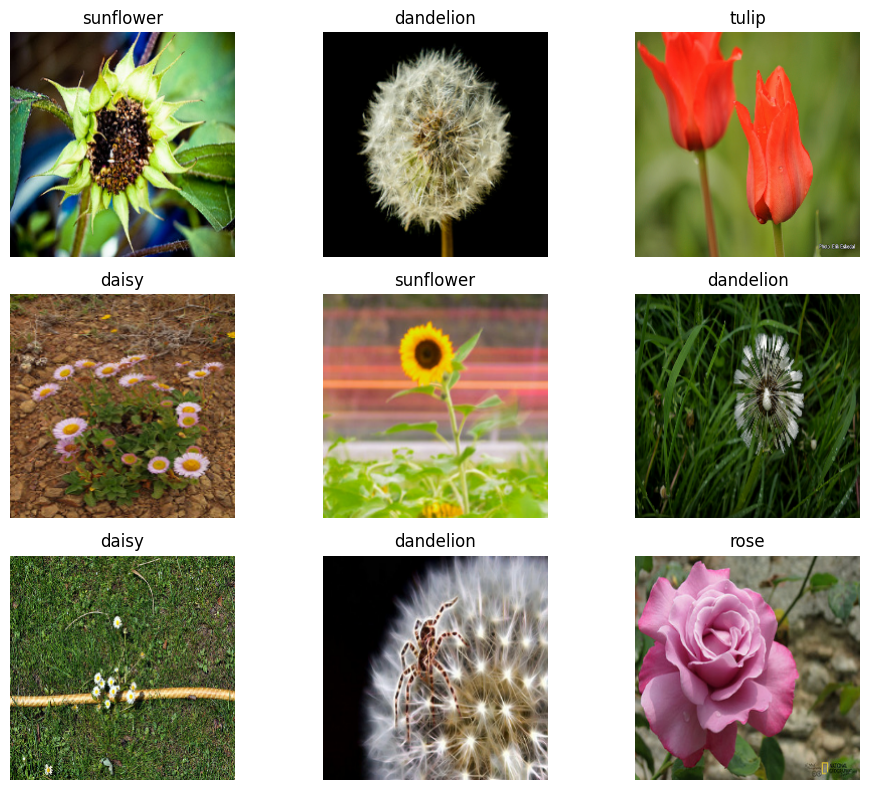

In [6]:

# Display sample images
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()



## Preprocessing and Performance Pipeline

ResNet-50 expects 224×224 RGB images. The `preprocess_input` function prepares the image values for the pre-trained ResNet-50 model.


In [7]:

AUTOTUNE = tf.data.AUTOTUNE

def preprocess(images, labels):
    images = tf.cast(images, tf.float32)
    images = preprocess_input(images)
    return images, labels

train_prepared = train_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_prepared = val_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_prepared = test_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)



## Task B — Implementing Transfer Learning

A pre-trained ResNet-50 model is loaded without its original ImageNet classification head. A new classification layer is added according to the number of classes in the Kaggle dataset.

The pre-trained feature-extraction layers are frozen as required by the experiment.


In [8]:

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax")
])

model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [9]:

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")


Model compiled successfully.



## Task C — Model Training

Train the transfer-learning model and record training accuracy, validation accuracy, training loss, and validation loss.


In [10]:

EPOCHS = 10

history = model.fit(
    train_prepared,
    validation_data=val_prepared,
    epochs=EPOCHS
)


Epoch 1/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 187s 3s/step - accuracy: 0.6745 - loss: 0.8721 - val_accuracy: 0.8952 - val_loss: 0.3514
Epoch 2/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 178s 3s/step - accuracy: 0.8794 - loss: 0.3513 - val_accuracy: 0.9301 - val_loss: 0.2398
Epoch 3/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 176s 3s/step - accuracy: 0.9204 - loss: 0.2528 - val_accuracy: 0.9136 - val_loss: 0.2720
Epoch 4/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 176s 3s/step - accuracy: 0.9397 - loss: 0.2034 - val_accuracy: 0.9301 - val_loss: 0.2142
Epoch 5/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 176s 3s/step - accuracy: 0.9433 - loss: 0.1748 - val_accuracy: 0.9651 - val_loss: 0.1278
Epoch 6/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 175s 3s/step - accuracy: 0.9496 - loss: 0.1488 - val_accuracy: 0.9614 - val_loss: 0.1382
Epoch 7/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 175s 3s/step - accuracy: 0.9620 - loss: 0.1273 - val_accuracy: 0.9651 - val_loss: 0.1223
Epoch 8/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 202s 3s/step - accuracy: 0.9688 - loss: 0.1143 - val_accuracy: 0.9761 - v

In [11]:

# Record final training and validation metrics
final_train_acc = history.history["accuracy"][-1]
final_val_acc = history.history["val_accuracy"][-1]
final_train_loss = history.history["loss"][-1]
final_val_loss = history.history["val_loss"][-1]

print(f"Final Training Accuracy   : {final_train_acc:.4f}")
print(f"Final Validation Accuracy : {final_val_acc:.4f}")
print(f"Final Training Loss       : {final_train_loss:.4f}")
print(f"Final Validation Loss     : {final_val_loss:.4f}")


Final Training Accuracy   : 0.9766
Final Validation Accuracy : 0.9577
Final Training Loss       : 0.0897
Final Validation Loss     : 0.1461


## Accuracy vs Epoch

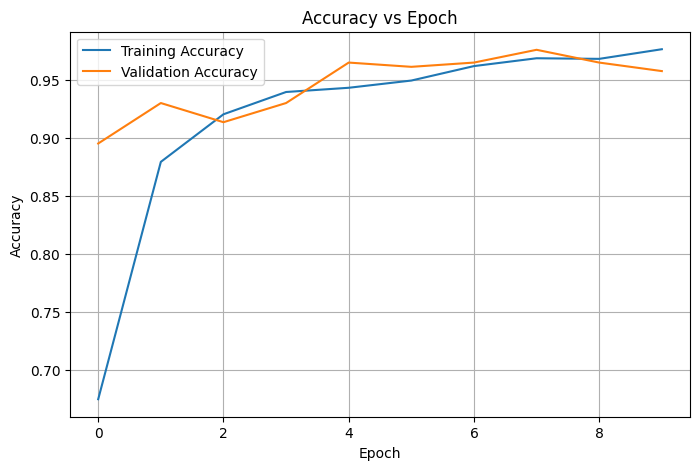

In [12]:

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.grid(True)
plt.show()


## Loss vs Epoch

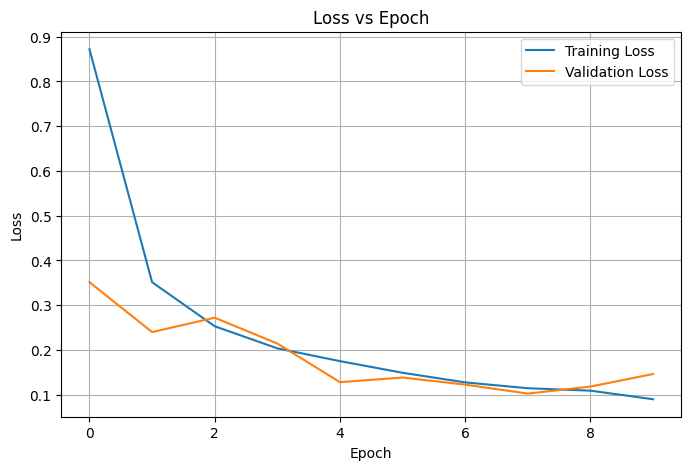

In [13]:

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.grid(True)
plt.show()


## Test Accuracy

In [14]:

test_loss, test_accuracy = model.evaluate(test_prepared, verbose=1)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")


9/9 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.9283 - loss: 0.2734
Test Loss     : 0.2734
Test Accuracy : 0.9283


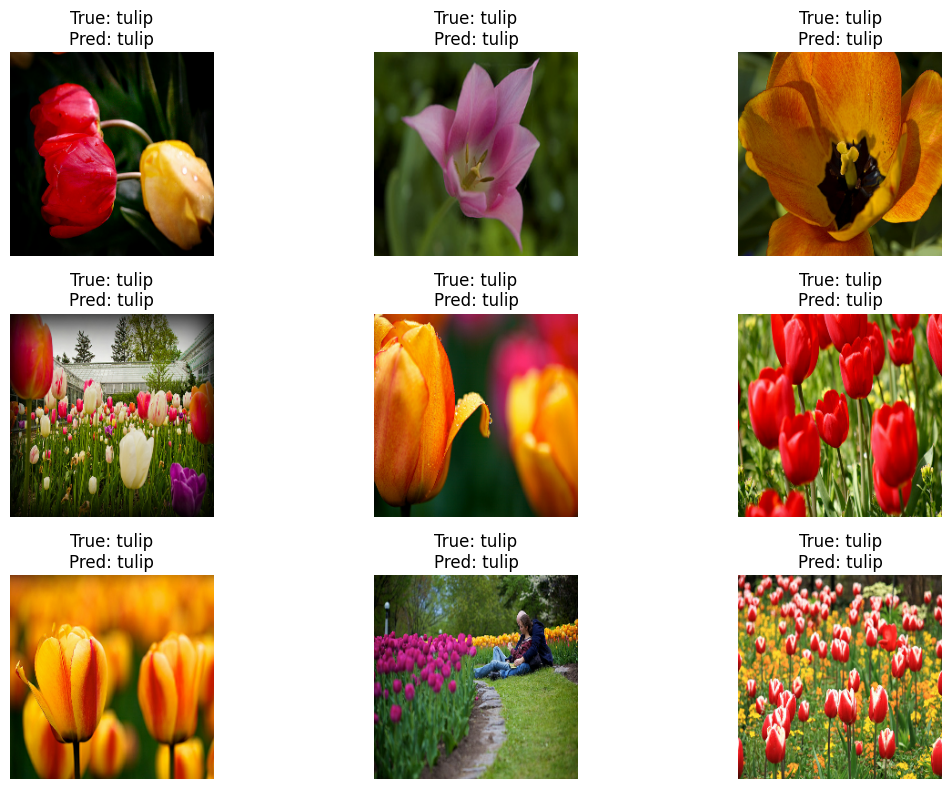

In [15]:

# Display predictions from the transfer-learning model on test images
for images, labels in test_ds.take(1):
    raw_images = images.numpy().astype("uint8")
    processed_images = preprocess_input(tf.cast(images, tf.float32))
    probabilities = model.predict(processed_images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    plt.figure(figsize=(12, 8))

    for i in range(min(9, len(raw_images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(raw_images[i])
        true_label = class_names[labels[i]]
        predicted_label = class_names[predictions[i]]
        plt.title(f"True: {true_label}\nPred: {predicted_label}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()



## Task D — Hugging Face Pre-trained Vision Model

The following section uses a pre-trained image-classification model available through Hugging Face Transformers.

The model is used for classification of sample images. Its labels may differ from the custom Kaggle dataset classes, so the comparison should focus on the predictions and observations rather than assuming the class names are identical.


In [16]:

from transformers import pipeline

hf_classifier = pipeline(
    task="image-classification",
    model="google/vit-base-patch16-224"
)

print("Hugging Face vision model loaded successfully.")


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Hugging Face vision model loaded successfully.


In [17]:

# Use a sample image from the test dataset.
# The Hugging Face pipeline accepts a PIL image.

from PIL import Image

sample_images = []

for images, labels in test_ds.take(1):
    for i in range(min(3, len(images))):
        arr = images[i].numpy().astype("uint8")
        sample_images.append(Image.fromarray(arr))

for i, image in enumerate(sample_images):
    results = hf_classifier(image, top_k=5)

    print(f"\nSample Image {i + 1}")
    for result in results:
        print(f"{result['label']}: {result['score']:.4f}")



Sample Image 1
vase: 0.1117
lampshade, lamp shade: 0.0372
cup: 0.0307
goblet: 0.0260
pot, flowerpot: 0.0221

Sample Image 2
pot, flowerpot: 0.0460
daisy: 0.0282
ant, emmet, pismire: 0.0169
earthstar: 0.0123
pinwheel: 0.0109

Sample Image 3
bee: 0.0927
ant, emmet, pismire: 0.0533
ladybug, ladybeetle, lady beetle, ladybird, ladybird beetle: 0.0269
pot, flowerpot: 0.0266
daisy: 0.0169



## Compare Transfer Learning and Hugging Face Predictions

Use the following cell to view both models' predictions for the same sample images. Note that the ResNet-50 model was trained specifically on the Kaggle dataset, whereas the Hugging Face ViT model uses its own pre-trained label space.


In [18]:

# Compare predictions for the same sample images

for i, image in enumerate(sample_images):
    image_array = np.array(image)

    # Transfer-learning prediction
    x = np.expand_dims(image_array.astype(np.float32), axis=0)
    x = preprocess_input(x)
    tl_probs = model.predict(x, verbose=0)[0]
    tl_idx = int(np.argmax(tl_probs))
    tl_label = class_names[tl_idx]
    tl_score = float(tl_probs[tl_idx])

    # Hugging Face prediction
    hf_result = hf_classifier(image, top_k=1)[0]

    print(f"Sample {i + 1}")
    print(f"Transfer Learning (ResNet-50): {tl_label} ({tl_score:.4f})")
    print(f"Hugging Face ViT             : {hf_result['label']} ({hf_result['score']:.4f})")
    print("-" * 60)


Sample 1
Transfer Learning (ResNet-50): tulip (0.8609)
Hugging Face ViT             : vase (0.1117)
------------------------------------------------------------
Sample 2
Transfer Learning (ResNet-50): tulip (0.8687)
Hugging Face ViT             : pot, flowerpot (0.0460)
------------------------------------------------------------
Sample 3
Transfer Learning (ResNet-50): tulip (0.8708)
Hugging Face ViT             : bee (0.0927)
------------------------------------------------------------
